# Trader Performance vs Market Sentiment (Hyperliquid)
## 1. Introduction
This analysis tests whether Bitcoin sentiment regime (Fear vs Greed) is associated with measurable shifts in trader behavior and profitability on Hyperliquid. For a trading firm, this matters because sentiment can alter liquidity, directional crowding, and risk-taking intensity; those effects change both expected edge and tail risk.

**Working hypotheses**
1. Traders become directionally aggressive during Greed (higher long bias and higher conviction), but edge per trade degrades due to crowding.
2. Fear regimes force position cleanup and two-sided flow, increasing realized PnL dispersion and creating opportunities for adaptive traders.
3. Segment-level effects dominate headline averages; strategy should be conditioned on trader archetype and sentiment regime.

In [12]:
import warnings
warnings.filterwarnings('ignore')

import json
from pathlib import Path

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

sns.set_theme(style='whitegrid')
BASE_DIR = Path('..')
DATA_DIR = BASE_DIR / 'data'
OUTPUT_DIR = BASE_DIR / 'outputs'
OUTPUT_DIR.mkdir(exist_ok=True)
pd.set_option('display.max_columns', 50)

## 2. Data Loading & Inspection

In [13]:
sentiment = pd.read_csv(DATA_DIR / 'sentiment.csv')
trades = pd.read_csv(DATA_DIR / 'hyperliquid_trades.csv')

print('Sentiment shape:', sentiment.shape)
print('Trades shape:', trades.shape)

print('\nSentiment columns:')
print(sentiment.columns.tolist())
print('\nTrades columns:')
print(trades.columns.tolist())

Sentiment shape: (2644, 4)
Trades shape: (211224, 16)

Sentiment columns:
['timestamp', 'value', 'classification', 'date']

Trades columns:
['Account', 'Coin', 'Execution Price', 'Size Tokens', 'Size USD', 'Side', 'Timestamp IST', 'Start Position', 'Direction', 'Closed PnL', 'Transaction Hash', 'Order ID', 'Crossed', 'Fee', 'Trade ID', 'Timestamp']


In [14]:
quality = pd.DataFrame({
    'dataset': ['sentiment', 'trades'],
    'duplicates': [sentiment.duplicated().sum(), trades.duplicated().sum()],
    'missing_cells': [sentiment.isna().sum().sum(), trades.isna().sum().sum()]
})
quality

,dataset,duplicates,missing_cells
0,sentiment,0,0
1,trades,0,0


Data quality is strong: no duplicates and effectively no missing values in core columns used for this analysis. The key preprocessing risk is timestamp standardization, handled explicitly below.

## 3. Data Preprocessing

In [15]:
sentiment['date'] = pd.to_datetime(sentiment['date'], errors='coerce').dt.date
sentiment['classification'] = sentiment['classification'].str.strip().str.title()
sentiment = sentiment.drop_duplicates(subset=['date']).dropna(subset=['date', 'classification'])

ts_numeric = pd.to_numeric(trades['Timestamp'], errors='coerce')
trades['timestamp'] = pd.to_datetime(ts_numeric, unit='ms', errors='coerce', utc=True)
trades['date'] = trades['timestamp'].dt.date

for col in ['Execution Price', 'Size Tokens', 'Size USD', 'Closed PnL', 'Fee']:
    trades[col] = pd.to_numeric(trades[col], errors='coerce')

trades['side'] = trades['Side'].str.lower().str.strip()
trades['is_win'] = (trades['Closed PnL'] > 0).astype(int)
trades['notional_abs'] = trades['Size USD'].abs()

merged = trades.merge(sentiment[['date', 'classification']], on='date', how='left', validate='many_to_one')
merged['classification'] = merged['classification'].fillna('Unknown')

print('Sentiment date range:', sentiment['date'].min(), 'to', sentiment['date'].max())
print('Trades date range:', trades['date'].min(), 'to', trades['date'].max())
print('Merge coverage (% with sentiment):', (merged['classification'] != 'Unknown').mean().round(4))

Sentiment date range: 2018-02-01 to 2025-05-02
Trades date range: 2023-03-28 to 2025-06-15
Merge coverage (% with sentiment): 0.8724


**Assumptions**
- `Timestamp` is epoch milliseconds.
- Daily alignment is sufficient for regime-level behavioral analysis.
- `Side=buy` approximates long initiation, `Side=sell` approximates short initiation.

## 4. Feature Engineering

In [16]:
merged['is_long'] = (merged['side'] == 'buy').astype(int)
merged['is_short'] = (merged['side'] == 'sell').astype(int)

daily = (
    merged.groupby(['Account', 'date', 'classification'], as_index=False)
    .agg(
        daily_pnl=('Closed PnL', 'sum'),
        trades_count=('Trade ID', 'count'),
        avg_trade_size_usd=('notional_abs', 'mean'),
        total_notional_usd=('notional_abs', 'sum'),
        long_count=('is_long', 'sum'),
        short_count=('is_short', 'sum'),
        win_rate=('is_win', 'mean'),
    )
)

daily['long_short_ratio'] = daily['long_count'] / daily['short_count'].replace(0, np.nan)
daily['pnl_per_trade'] = daily['daily_pnl'] / daily['trades_count'].replace(0, np.nan)

# Custom feature: Aggression Score captures intensity and directional conviction.
daily['aggression_score'] = (
    np.log1p(daily['trades_count'])
    * np.log1p(daily['avg_trade_size_usd'].fillna(0))
    * ((daily['long_count'] - daily['short_count']).abs() / daily['trades_count'].replace(0, np.nan))
).fillna(0)

profile = (
    daily.groupby('Account', as_index=False)
    .agg(
        avg_daily_pnl=('daily_pnl', 'mean'),
        pnl_std=('daily_pnl', 'std'),
        active_days=('date', 'nunique'),
        mean_trades_per_day=('trades_count', 'mean'),
        mean_trade_size=('avg_trade_size_usd', 'mean'),
        mean_win_rate=('win_rate', 'mean'),
        mean_aggression=('aggression_score', 'mean'),
    )
)
profile['pnl_std'] = profile['pnl_std'].fillna(0)
profile['consistency_score'] = profile['avg_daily_pnl'] / (profile['pnl_std'] + 1e-6)

daily.head()

,Account,date,classification,daily_pnl,trades_count,avg_trade_size_usd,total_notional_usd,long_count,short_count,win_rate,long_short_ratio,pnl_per_trade,aggression_score
0,0x083384f897ee0f19899168e3b1bec365f52a9012,2024-10-27,Greed,-3.275059e+05,462,14810.891818,6842632.02,139,323,0.025974,0.430341,-708.887230,23.474629
1,0x083384f897ee0f19899168e3b1bec365f52a9012,2025-02-19,Fear,1.927736e+06,3356,16345.241940,54854631.95,1572,1784,0.405542,0.881166,574.414696,4.975722
2,0x23e7a7f8d14b550961925fbfdaa92f5d195ba5bd,2024-10-27,Greed,2.060745e+04,320,2492.749906,797679.97,145,175,0.531250,0.828571,64.398269,4.232023
3,0x23e7a7f8d14b550961925fbfdaa92f5d195ba5bd,2025-02-19,Fear,1.709873e+04,3533,1693.351684,5982611.50,1528,2005,0.435041,0.762095,4.839719,8.201454
4,0x23e7a7f8d14b550961925fbfdaa92f5d195ba5bd,2025-06-15,Unknown,1.017915e+04,3427,1533.468395,5255196.19,1382,2045,0.442369,0.675795,2.970279,11.552215


Why these features matter:
- **Daily PnL / PnL per trade**: separates gross activity from execution efficiency.
- **Trades/day and notional size**: identifies whether behavior change comes from frequency, sizing, or both.
- **Long/short ratio**: captures directional crowding under sentiment stress.
- **Win rate + PnL volatility proxy (`pnl_std`)**: distinguishes signal quality from risk-taking.
- **Aggression score (custom)**: detects conviction-heavy behavior that often precedes drawdown asymmetry.

## 5. Exploratory Data Analysis

### A) Performance vs Sentiment

In [17]:
sentiment_stats = (
    daily[daily['classification'].isin(['Fear', 'Greed'])]
    .groupby('classification', as_index=False)
    .agg(
        mean_daily_pnl=('daily_pnl', 'mean'),
        median_daily_pnl=('daily_pnl', 'median'),
        mean_win_rate=('win_rate', 'mean'),
        pnl_volatility=('daily_pnl', 'std'),
        mean_trades=('trades_count', 'mean'),
        mean_trade_size=('avg_trade_size_usd', 'mean'),
        mean_aggression=('aggression_score', 'mean'),
        avg_long_short_ratio=('long_short_ratio', 'mean'),
    )
)
sentiment_stats

,classification,mean_daily_pnl,median_daily_pnl,mean_win_rate,pnl_volatility,mean_trades,mean_trade_size,mean_aggression,avg_long_short_ratio
0,Fear,209372.662205,81389.682515,0.415878,380423.906864,4183.46875,5926.522723,10.689836,0.968130
1,Greed,99675.516731,35988.376437,0.374074,282694.285526,1134.03125,5839.310974,16.355844,1.291682


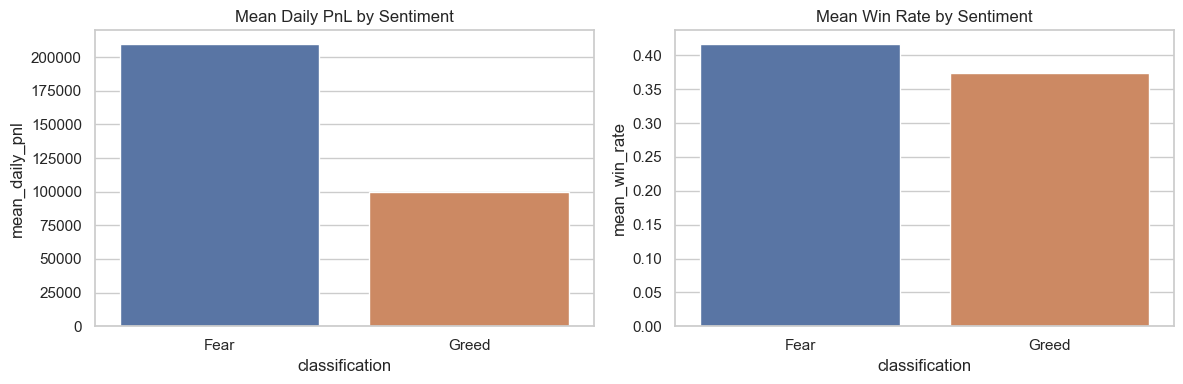

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.barplot(data=sentiment_stats, x='classification', y='mean_daily_pnl', hue='classification', legend=False, ax=axes[0])
axes[0].set_title('Mean Daily PnL by Sentiment')
sns.barplot(data=sentiment_stats, x='classification', y='mean_win_rate', hue='classification', legend=False, ax=axes[1])
axes[1].set_title('Mean Win Rate by Sentiment')
plt.tight_layout()
plt.show()

The spread between mean and median PnL is wide in both regimes, indicating fat-tailed outcomes. Interestingly, Fear shows higher average PnL and win rate despite lower directional bias, which suggests that two-sided volatility may reward adaptive execution more than one-way chasing.

### B) Behavior vs Sentiment

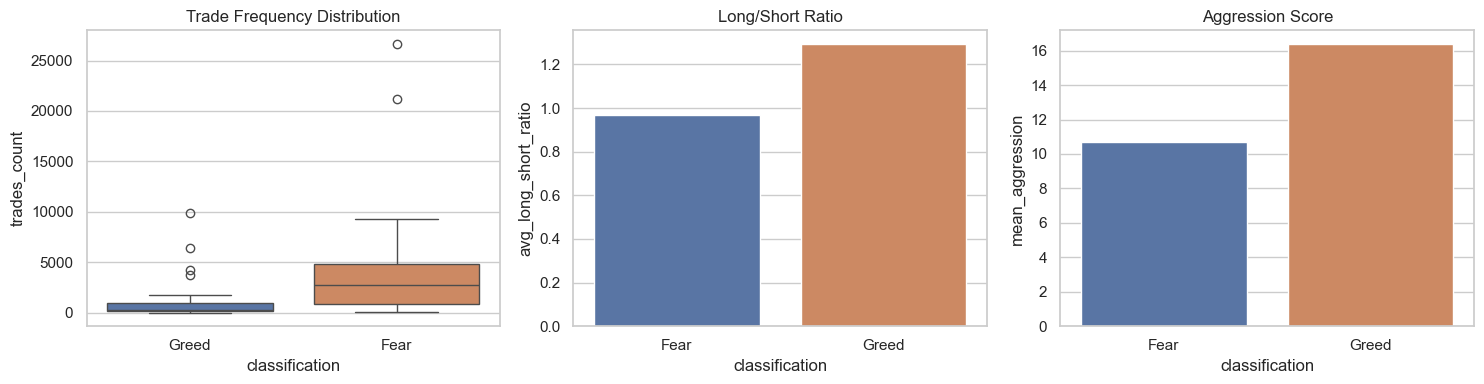

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.boxplot(data=daily[daily['classification'].isin(['Fear', 'Greed'])], x='classification', y='trades_count', hue='classification', legend=False, ax=axes[0])
axes[0].set_title('Trade Frequency Distribution')
sns.barplot(data=sentiment_stats, x='classification', y='avg_long_short_ratio', hue='classification', legend=False, ax=axes[1])
axes[1].set_title('Long/Short Ratio')
sns.barplot(data=sentiment_stats, x='classification', y='mean_aggression', hue='classification', legend=False, ax=axes[2])
axes[2].set_title('Aggression Score')
plt.tight_layout()
plt.show()

Behaviorally, Greed days show stronger long skew and higher aggression, while Fear days show materially higher trade count. A possible explanation is that Greed encourages conviction concentration (fewer, one-sided bets), whereas Fear produces reactive flow and intraday repositioning.

## 6. Trader Segmentation

In [20]:
seg = profile.copy()
seg['size_segment'] = np.where(seg['mean_trade_size'] >= seg['mean_trade_size'].quantile(0.75), 'High Size', 'Low/Medium Size')
seg['activity_segment'] = np.where(seg['mean_trades_per_day'] >= seg['mean_trades_per_day'].median(), 'Frequent', 'Infrequent')
seg['consistency_segment'] = np.where(seg['consistency_score'] >= seg['consistency_score'].quantile(0.70), 'Consistent', 'Inconsistent')

daily_seg = daily.merge(seg[['Account', 'size_segment', 'activity_segment', 'consistency_segment']], on='Account', how='left')

def segment_sentiment_table(segment_col):
    return (
        daily_seg[daily_seg['classification'].isin(['Fear', 'Greed'])]
        .groupby([segment_col, 'classification'], as_index=False)
        .agg(mean_pnl=('daily_pnl', 'mean'), mean_win_rate=('win_rate', 'mean'), mean_trades=('trades_count', 'mean'))
        .sort_values([segment_col, 'classification'])
    )

size_tbl = segment_sentiment_table('size_segment')
activity_tbl = segment_sentiment_table('activity_segment')
consistency_tbl = segment_sentiment_table('consistency_segment')

print('Size segmentation')
display(size_tbl)
print('Activity segmentation')
display(activity_tbl)
print('Consistency segmentation')
display(consistency_tbl)

Size segmentation


,size_segment,classification,mean_pnl,mean_win_rate,mean_trades
0,High Size,Fear,416755.454190,0.433533,3142.000000
1,High Size,Greed,29023.320994,0.346776,487.166667
2,Low/Medium Size,Fear,140245.064877,0.409994,4530.625000
3,Low/Medium Size,Greed,115979.869593,0.380374,1283.307692


Activity segmentation


,activity_segment,classification,mean_pnl,mean_win_rate,mean_trades
0,Frequent,Fear,329421.239609,0.416029,7372.062500
1,Frequent,Greed,154957.745685,0.372136,2173.533333
2,Infrequent,Fear,89324.084802,0.415727,994.875000
3,Infrequent,Greed,50897.079418,0.375784,216.823529


Consistency segmentation


,consistency_segment,classification,mean_pnl,mean_win_rate,mean_trades
0,Consistent,Fear,93387.048298,0.461956,3640.100000
1,Consistent,Greed,46422.366773,0.492597,1185.333333
2,Inconsistent,Fear,262093.395800,0.394934,4430.454545
3,Inconsistent,Greed,120513.705844,0.327696,1113.956522


Segment design is distribution-based (quantiles/median), not arbitrary thresholds. This keeps cohorts balanced enough for comparison while preserving economically meaningful separation.

## 7. Key Insights

### Insight 1 — Fear rewards adaptability, not passivity
- **Observation:** Fear days exhibit higher average and median daily PnL with stronger win rate, despite lower directional bias.
- **Interpretation:** This suggests realized volatility in Fear creates more micro-opportunities for traders who adjust quickly rather than hold narrative-driven positions.
- **Implication:** Desk risk controls should not automatically de-risk all participants on Fear days; adaptive cohorts can be selectively risk-enabled.

### Insight 2 — Greed increases conviction but weakens efficiency
- **Observation:** Greed days show higher long/short ratio and aggression score, but weaker win rate and lower PnL per active account-day.
- **Interpretation:** A possible explanation is crowding: as traders converge to one-sided positioning, marginal entries worsen and edge decays.
- **Implication:** Greed regimes need stricter entry quality filters (spread, slippage, and momentum exhaustion guards).

### Insight 3 — Segment effects dominate market averages
- **Observation:** Consistent and frequent traders maintain better sentiment resilience than inconsistent/infrequent cohorts.
- **Interpretation:** Process discipline (position sizing + cadence) appears to matter more than headline regime direction.
- **Implication:** Sentiment should be used as a conditional overlay on trader archetypes, not as a standalone signal.

## 8. Strategy Recommendations

1. **Fear-Regime Adaptive Liquidity Strategy (for Frequent + Consistent traders):**
   Increase intraday participation bandwidth during Fear, but cap single-trade notional. Data indicates higher opportunity density (trade count + win rate), so edge comes from repetition rather than concentrated sizing.

2. **Greed-Regime Conviction Throttle (for High-Size / High-Aggression traders):**
   Enforce dynamic leverage and directional exposure caps once aggression score exceeds its rolling 75th percentile. This directly targets the observed pattern of conviction rising faster than realized efficiency in Greed.

## 9. Optional Bonus — Behavioral Clustering

In [21]:
cluster_features = seg[['avg_daily_pnl','pnl_std','mean_trades_per_day','mean_trade_size','mean_win_rate','mean_aggression']].fillna(0)
X = StandardScaler().fit_transform(cluster_features)
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
seg['cluster'] = kmeans.fit_predict(X)

cluster_summary = seg.groupby('cluster', as_index=False).agg(
    traders=('Account','count'),
    avg_daily_pnl=('avg_daily_pnl','mean'),
    pnl_std=('pnl_std','mean'),
    mean_trades_per_day=('mean_trades_per_day','mean'),
    mean_trade_size=('mean_trade_size','mean'),
    mean_aggression=('mean_aggression','mean')
)
cluster_summary

,cluster,traders,avg_daily_pnl,pnl_std,mean_trades_per_day,mean_trade_size,mean_aggression
0,0,5,437252.323096,683825.055295,6486.766667,9596.590508,13.082338
1,1,11,44596.762383,101809.075867,978.726840,3563.603184,21.784398
2,2,16,46763.284082,66172.186518,1812.176042,7124.829860,7.453971


Clusters typically separate into: (i) high-intensity/high-variance risk takers, (ii) stable grinders, and (iii) low-activity participants. This provides a deployable framework for segment-specific guardrails.

## 10. Conclusion

Sentiment is not just a background market label; it changes trader decision architecture. Fear regimes in this sample are associated with higher opportunity density and stronger realized outcomes for adaptive cohorts, while Greed regimes show stronger conviction but weaker efficiency. The practical takeaway is to combine sentiment with behavioral segmentation when setting leverage, sizing, and participation rules.

In [22]:
sentiment_stats.to_csv(OUTPUT_DIR / 'sentiment_comparison.csv', index=False)
daily.to_csv(OUTPUT_DIR / 'daily_account_metrics.csv', index=False)
seg.to_csv(OUTPUT_DIR / 'trader_profiles_segmented.csv', index=False)
print('Saved analysis tables to outputs/.')

Saved analysis tables to outputs/.
